# Proyecto final — Emisiones de CO₂ per cápita
## Notebook 3: Modelo de regresión lineal e interpretación

**Curso:** Ciencia de Datos — Actividad 4: Proyecto final
**Institución:** Fundación Universitaria Agraria de Colombia (UNIAGRARIA)
**Responsable de este notebook:** Ricardo José Díaz (GitHub: `requiempax`)
**Equipo:** Juan Felipe Castañeda Rodríguez · José Alejandro Ochoa · Ricardo José Díaz

---

### Pregunta

La sección **"Per capita CO₂ emissions"** del artículo de Our World in Data afirma que *existe una relación fuerte entre el ingreso y las emisiones per cápita*, pero que países con niveles de vida parecidos pueden emitir muy distinto. Este notebook **cuantifica** esa relación con una regresión lineal:

> ¿Cuánto aumentan las emisiones de CO₂ per cápita de un país cuando aumenta su PIB per cápita, y qué parte de las diferencias entre países explica el ingreso?

### Especificación del modelo

El análisis exploratorio (notebook 2) mostró que la relación es casi lineal **en escala logarítmica** (r = 0,91) y no tanto en la escala original (r = 0,76). Por eso se usa un modelo log–log:

$$\log_{10}(\text{CO}_2\ \text{per cápita}) = \beta_0 + \beta_1 \cdot \log_{10}(\text{PIB per cápita}) + \varepsilon$$

En este modelo, **β₁ es una elasticidad**: indica en qué porcentaje cambian las emisiones por persona cuando el PIB per cápita aumenta 1 %.

- **Datos:** países en **2022**, el último año con PIB disponible (datos limpios del notebook 1).
- **Variable dependiente (y):** `log_co2_pc`.
- **Variable explicativa (x):** `log_gdp_pc`.
- **Herramientas:** `scikit-learn` (`LinearRegression`, `train_test_split` y métricas) y `scipy.stats` (prueba de significancia de la pendiente).

## 1. Preparación de los datos para el modelo

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

AZUL, NARANJA, VERDE, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a85"
TEXTO, TEXTO_2, REJILLA = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.figsize": (10, 5), "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": REJILLA, "axes.labelcolor": TEXTO_2, "axes.titlesize": 13,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.grid": True,
    "grid.color": REJILLA, "xtick.color": TEXTO_2, "ytick.color": TEXTO_2,
    "font.size": 10, "legend.frameon": False, "lines.linewidth": 2,
})

paises = pd.read_csv("../data/co2_paises_limpio.csv")
datos = (paises[paises["year"] == 2022]
         .dropna(subset=["log_gdp_pc", "log_co2_pc"])
         [["country", "iso_code", "gdp_per_capita", "co2_per_capita", "log_gdp_pc", "log_co2_pc",
           "population", "atipico_co2_pc"]]
         .reset_index(drop=True))

print("Países con PIB y emisiones en 2022:", len(datos))
print("Faltantes en las variables del modelo:", datos[["log_gdp_pc", "log_co2_pc"]].isna().sum().sum())
print("Población cubierta:", f"{datos['population'].sum() / 1e9:.2f} mil millones de personas")
display(datos[["gdp_per_capita", "co2_per_capita", "log_gdp_pc", "log_co2_pc"]].describe().round(3))

Países con PIB y emisiones en 2022: 163
Faltantes en las variables del modelo: 0
Población cubierta: 7.91 mil millones de personas


,gdp_per_capita,co2_per_capita,log_gdp_pc,log_co2_pc
count,163.000,163.000,163.000,163.000
mean,19204.132,4.446,4.021,0.325
std,20096.640,5.361,0.532,0.611
min,688.913,0.056,2.838,-1.252
25%,4415.377,0.812,3.645,-0.091
50%,12658.771,2.910,4.102,0.464
75%,27439.488,5.890,4.438,0.770
max,131990.525,35.771,5.121,1.554


Los datos ya vienen limpios del notebook 1: sin duplicados, sin ceros (que no tienen logaritmo) y sin microterritorios. Los países sin dato de PIB en 2022 quedan fuera del modelo.

## 2. División en entrenamiento y prueba

Para evaluar el modelo con datos que **no vio al ajustarse**, se separa el 80 % de los países para entrenarlo y el 20 % para probarlo. Se fija `random_state=42` para que el resultado sea reproducible.

In [2]:
X = datos[["log_gdp_pc"]]
y = datos["log_co2_pc"]
X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X, y, datos.index, test_size=0.2, random_state=42)

print(f"Entrenamiento: {len(X_train)} países | Prueba: {len(X_test)} países")

Entrenamiento: 130 países | Prueba: 33 países


## 3. Ajuste del modelo

In [3]:
modelo = LinearRegression()
modelo.fit(X_train, y_train)

b0 = modelo.intercept_
b1 = modelo.coef_[0]
print("Ecuación estimada:")
print(f"  log10(CO2 per cápita) = {b0:.3f} + {b1:.3f} · log10(PIB per cápita)")
print("\nEquivalente en la escala original:")
print(f"  CO2 per cápita = {10**b0:.6f} · (PIB per cápita)^{b1:.3f}")

# Significancia estadística de la pendiente (mismos datos de entrenamiento)
prueba = stats.linregress(X_train["log_gdp_pc"], y_train)
ic = stats.t.ppf(0.975, len(X_train) - 2) * prueba.stderr
print(f"\nPendiente (elasticidad): {prueba.slope:.3f}")
print(f"Intervalo de confianza del 95 %: [{prueba.slope - ic:.3f}, {prueba.slope + ic:.3f}]")
print(f"Valor p de la pendiente: {prueba.pvalue:.2e}")

Ecuación estimada:
  log10(CO2 per cápita) = -3.871 + 1.043 · log10(PIB per cápita)

Equivalente en la escala original:
  CO2 per cápita = 0.000135 · (PIB per cápita)^1.043

Pendiente (elasticidad): 1.043
Intervalo de confianza del 95 %: [0.963, 1.123]
Valor p de la pendiente: 1.11e-52


**Interpretación de los coeficientes.**

- **Pendiente β₁ = 1,04 (IC 95 %: 0,96 a 1,12).** Es la **elasticidad** de las emisiones respecto al ingreso: si el PIB per cápita de un país es 1 % mayor, sus emisiones por persona son en promedio un **1,04 % mayores**. Como el intervalo de confianza contiene el 1, la relación es prácticamente **proporcional**: un país con el doble de ingreso emite, en promedio, alrededor del **doble de CO₂ por persona** (2^1,04 ≈ 2,06 veces).
- **Valor p ≈ 10⁻⁵².** La probabilidad de observar una relación así si en realidad no existiera es prácticamente cero: la relación es estadísticamente significativa.
- **Intercepto β₀ = −3,87.** Por sí solo no tiene una interpretación práctica (correspondería a un PIB per cápita de 1 dólar). Su función es ubicar la recta: por ejemplo, para un PIB per cápita de 10 000 dólares el modelo predice 10^(−3,871 + 1,043·4) ≈ 2,0 t por persona.

Esto cuantifica la afirmación central de la sección del artículo: **la prosperidad es uno de los principales impulsores de las emisiones per cápita**.

## 4. Recta de regresión sobre los datos

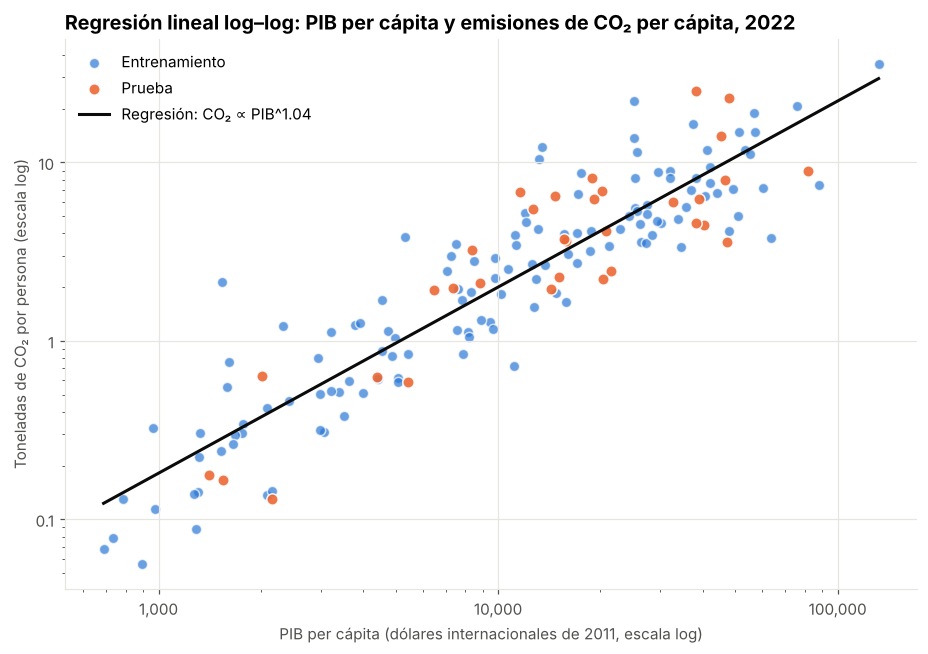

In [4]:
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.scatter(10**X_train["log_gdp_pc"], 10**y_train, s=45, color=AZUL, alpha=0.7,
           edgecolor="white", linewidth=1, label="Entrenamiento")
ax.scatter(10**X_test["log_gdp_pc"], 10**y_test, s=55, color=NARANJA, alpha=0.9,
           edgecolor="white", linewidth=1, label="Prueba")
xs = np.linspace(datos["log_gdp_pc"].min(), datos["log_gdp_pc"].max(), 100)
ax.plot(10**xs, 10**modelo.predict(pd.DataFrame({"log_gdp_pc": xs})), color=TEXTO, linewidth=2,
        label=f"Regresión: CO₂ ∝ PIB^{b1:.2f}")
ax.set_xscale("log"); ax.set_yscale("log")
for eje in (ax.xaxis, ax.yaxis):
    eje.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}" if v >= 1 else f"{v:g}"))
ax.set_title("Regresión lineal log–log: PIB per cápita y emisiones de CO₂ per cápita, 2022")
ax.set_xlabel("PIB per cápita (dólares internacionales de 2011, escala log)")
ax.set_ylabel("Toneladas de CO₂ por persona (escala log)")
ax.legend(loc="upper left")
plt.show()

## 5. Evaluación del modelo

Se calculan las métricas sobre el conjunto de **prueba**:

- **R²:** proporción de la variación de las emisiones (en logaritmo) que explica el ingreso.
- **MAE y RMSE en escala log:** error típico de la predicción, en unidades de log₁₀.
- **Error en veces:** como el modelo trabaja en logaritmos, el error se interpreta mejor como un factor multiplicativo: `10^MAE` indica por cuántas veces se equivoca el modelo en un país típico.

In [5]:
pred_train = modelo.predict(X_train)
pred_test = modelo.predict(X_test)

metricas = pd.DataFrame({
    "R²": [r2_score(y_train, pred_train), r2_score(y_test, pred_test)],
    "MAE (log10)": [mean_absolute_error(y_train, pred_train), mean_absolute_error(y_test, pred_test)],
    "RMSE (log10)": [mean_squared_error(y_train, pred_train) ** 0.5, mean_squared_error(y_test, pred_test) ** 0.5],
}, index=["Entrenamiento", "Prueba"])
metricas["Error típico (veces)"] = 10 ** metricas["MAE (log10)"]
display(metricas.round(3))

# Validación cruzada para comprobar que el resultado no depende de una sola partición
from sklearn.model_selection import cross_val_score
cv = cross_val_score(LinearRegression(), X, y, cv=5, scoring="r2")
print(f"R² en validación cruzada (5 particiones): {cv.mean():.3f} ± {cv.std():.3f}")

,R²,MAE (log10),RMSE (log10),Error típico (veces)
Entrenamiento,0.839,0.189,0.248,1.547
Prueba,0.772,0.230,0.263,1.700


R² en validación cruzada (5 particiones): 0.814 ± 0.075


**Interpretación de las métricas.**

- **R² de prueba = 0,77** y **R² de validación cruzada = 0,81 ± 0,08**: el ingreso explica alrededor del **80 %** de las diferencias en emisiones per cápita (en logaritmo) entre los países. Para una sola variable explicativa es un ajuste muy alto.
- El R² de entrenamiento (0,84) es solo un poco mayor que el de prueba: el modelo **no está sobreajustado** y generaliza bien a países que no vio.
- **Error típico ≈ 1,7 veces** (MAE de 0,23 en log₁₀): para un país típico la predicción se equivoca en un factor de 1,5 a 1,7. Por ejemplo, si un país emite 4 t, el modelo podría estimar entre 2,4 y 6,8 t.

El 20 % que el ingreso no explica es justamente lo que el artículo atribuye a las **decisiones de política y de tecnología**, sobre todo la matriz energética. Eso se analiza con los residuos en la sección 8.

## 6. Comparación con un modelo en la escala original

Para justificar el uso de logaritmos se ajusta el mismo modelo con las variables **sin transformar** (toneladas frente a dólares) y se comparan los R² de prueba.

In [6]:
Xo = datos[["gdp_per_capita"]]
yo = datos["co2_per_capita"]
modelo_orig = LinearRegression().fit(Xo.loc[idx_train], yo.loc[idx_train])
r2_orig = r2_score(yo.loc[idx_test], modelo_orig.predict(Xo.loc[idx_test]))
r2_log = r2_score(y_test, pred_test)
print(f"Modelo en escala original: CO2 pc = {modelo_orig.intercept_:.3f} + {modelo_orig.coef_[0]*1000:.4f} · (PIB pc / 1000)")
print(f"  R² de prueba (escala original): {r2_orig:.3f}")
print(f"  R² de prueba (log-log):         {r2_log:.3f}")

Modelo en escala original: CO2 pc = 0.410 + 0.2061 · (PIB pc / 1000)
  R² de prueba (escala original): 0.339
  R² de prueba (log-log):         0.772


**Interpretación.** El modelo en la escala original solo explica el **34 %** de la variación (R² = 0,34), frente al **77 %** del modelo log–log. En la escala original, unos pocos países muy ricos o muy emisores (Qatar, Emiratos) dominan el ajuste y la relación no es una línea recta. Al usar logaritmos la relación se vuelve lineal, los países pesan de forma más equilibrada y la pendiente gana una interpretación clara como elasticidad. **La transformación logarítmica está justificada.**

## 7. Análisis de residuos

Un **residuo** es la diferencia entre lo que el país emite realmente y lo que el modelo predice para su nivel de ingreso. Un residuo positivo indica que el país emite **más** de lo esperado por su ingreso; uno negativo, que emite **menos**.

Se revisan dos cosas: que los residuos no muestren un patrón contra los valores predichos (supuesto de linealidad) y que su distribución sea aproximadamente normal.

Media de los residuos: 0.0012
Prueba de Shapiro-Wilk: W = 0.985, p = 0.075


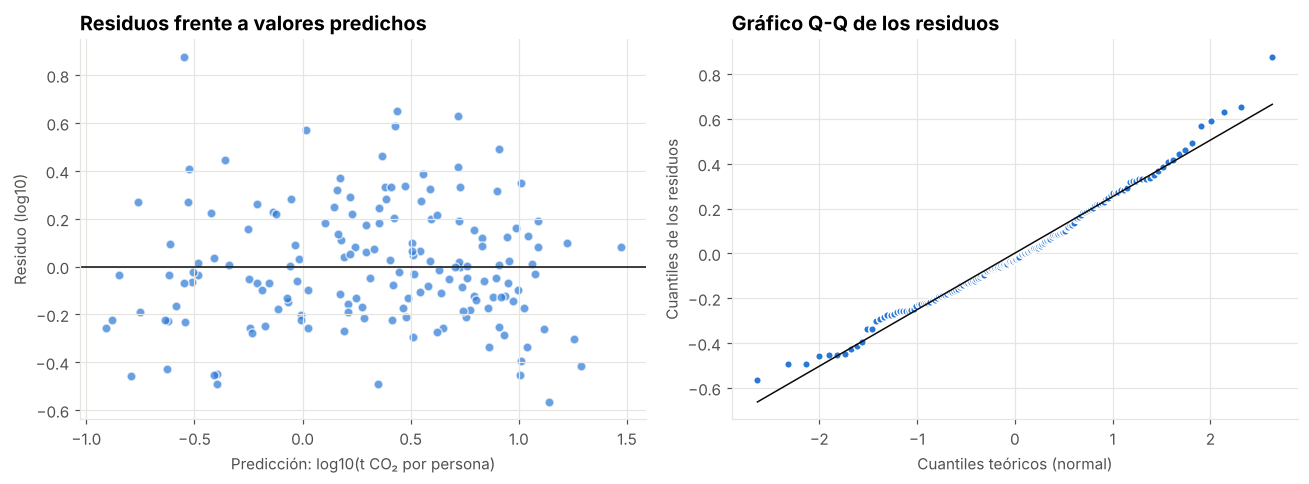

In [7]:
datos["prediccion_log"] = modelo.predict(datos[["log_gdp_pc"]])
datos["residuo"] = datos["log_co2_pc"] - datos["prediccion_log"]
datos["veces_vs_esperado"] = 10 ** datos["residuo"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.scatter(datos["prediccion_log"], datos["residuo"], s=35, color=AZUL, alpha=0.7, edgecolor="white", linewidth=1)
ax1.axhline(0, color=TEXTO, linewidth=1)
ax1.set_title("Residuos frente a valores predichos")
ax1.set_xlabel("Predicción: log10(t CO₂ por persona)")
ax1.set_ylabel("Residuo (log10)")
stats.probplot(datos["residuo"], dist="norm", plot=ax2)
ax2.get_lines()[0].set(color=AZUL, markersize=5, markeredgecolor="white")
ax2.get_lines()[1].set(color=TEXTO, linewidth=1)
ax2.set_title("Gráfico Q-Q de los residuos")
ax2.set_xlabel("Cuantiles teóricos (normal)")
ax2.set_ylabel("Cuantiles de los residuos")
plt.tight_layout()
plt.show()

w = stats.shapiro(datos["residuo"])
print(f"Media de los residuos: {datos['residuo'].mean():.4f}")
print(f"Prueba de Shapiro-Wilk: W = {w.statistic:.3f}, p = {w.pvalue:.3f}")

**Interpretación.**

- **Residuos frente a predichos:** los puntos se distribuyen alrededor de cero sin forma de curva ni de embudo. El supuesto de **linealidad** se cumple, y la variabilidad del error es parecida en todos los niveles de ingreso (**homocedasticidad**).
- **Gráfico Q-Q:** los residuos siguen de cerca la línea de la distribución normal, salvo un punto en el extremo superior (Corea del Norte, que se analiza más adelante).
- **Shapiro-Wilk:** p = 0,075 > 0,05, así que **no se rechaza la normalidad** de los residuos. Con esto, el intervalo de confianza y el valor p de la pendiente son confiables.
- La media de los residuos es prácticamente cero (0,001), como debe ocurrir en una regresión por mínimos cuadrados.

## 8. ¿Qué países emiten más o menos de lo que predice su ingreso?

Esta es la parte del análisis que conecta directamente con el artículo: el modelo dice cuánto *debería* emitir un país según su ingreso, y los residuos muestran **quiénes se apartan** de esa regla.

In [8]:
cols = ["country", "gdp_per_capita", "co2_per_capita", "veces_vs_esperado"]
nombres = {"country": "País", "gdp_per_capita": "PIB pc", "co2_per_capita": "t CO₂ pc",
           "veces_vs_esperado": "veces lo esperado"}
print("Países que emiten MÁS de lo esperado para su ingreso:")
display(datos.nlargest(10, "residuo")[cols].rename(columns=nombres).round(2).reset_index(drop=True))
print("Países que emiten MENOS de lo esperado para su ingreso:")
display(datos.nsmallest(10, "residuo")[cols].rename(columns=nombres).round(2).reset_index(drop=True))

Países que emiten MÁS de lo esperado para su ingreso:


,País,PIB pc,t CO₂ pc,veces lo esperado
0,North Korea,1537.81,2.14,7.54
1,Turkmenistan,13485.52,12.25,4.48
2,Trinidad and Tobago,25077.08,22.20,4.25
3,Mongolia,13233.69,10.41,3.88
4,Venezuela,5305.43,3.84,3.72
5,Bahrain,38324.94,25.29,3.11
6,South Africa,11599.51,6.79,2.91
7,Syria,2330.72,1.22,2.78
8,Kazakhstan,25138.20,13.69,2.62
9,Zimbabwe,1611.89,0.76,2.56


Países que emiten MENOS de lo esperado para su ingreso:


,País,PIB pc,t CO₂ pc,veces lo esperado
0,Switzerland,63623.01,3.75,0.27
1,Uganda,2155.77,0.13,0.32
2,Sri Lanka,11156.08,0.72,0.32
3,Democratic Republic of Congo,891.77,0.06,0.35
4,Rwanda,2085.28,0.14,0.35
5,Sweden,47124.89,3.56,0.35
6,Ethiopia,2153.20,0.14,0.36
7,Malawi,1286.68,0.09,0.37
8,Norway,88390.41,7.48,0.38
9,Hong Kong,47775.87,4.12,0.40


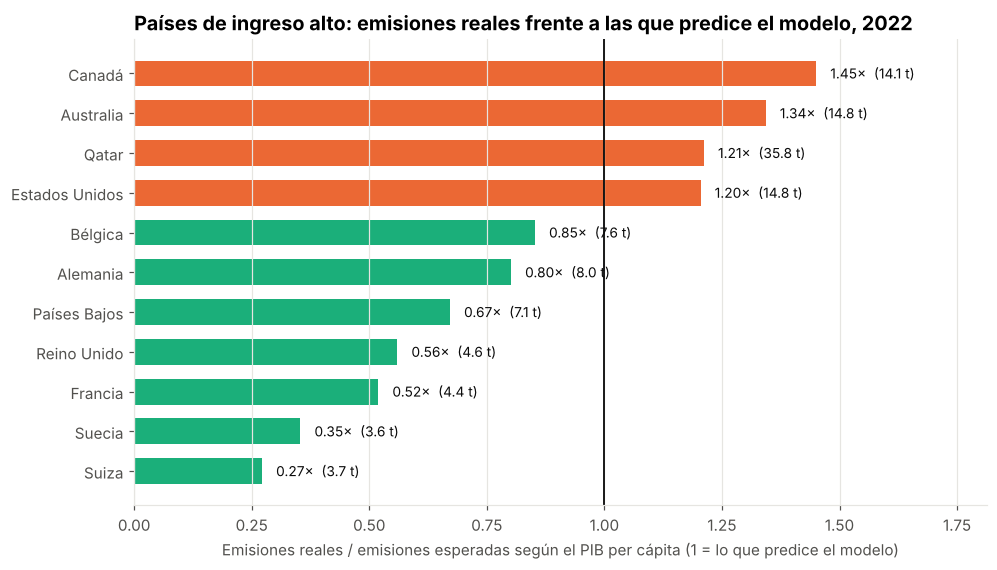

In [9]:
ricos = datos[datos["gdp_per_capita"] > 35000].sort_values("residuo")
seleccion = ["Switzerland", "Sweden", "France", "United Kingdom", "Germany",
             "Netherlands", "Belgium", "Canada", "Australia", "United States", "Qatar"]
r = ricos[ricos["country"].isin(seleccion)]
nombres_es = {"Switzerland": "Suiza", "Sweden": "Suecia", "France": "Francia", "United Kingdom": "Reino Unido",
              "Germany": "Alemania", "Netherlands": "Países Bajos", "Belgium": "Bélgica", "Canada": "Canadá",
              "Australia": "Australia", "United States": "Estados Unidos", "Qatar": "Qatar"}
fig, ax = plt.subplots(figsize=(10, 5.5))
colores = [VERDE if v < 1 else NARANJA for v in r["veces_vs_esperado"]]
ax.barh(r["country"].map(nombres_es), r["veces_vs_esperado"], color=colores, height=0.65, left=0)
ax.axvline(1, color=TEXTO, linewidth=1.2)
for yy, (v, real) in enumerate(zip(r["veces_vs_esperado"], r["co2_per_capita"])):
    ax.text(v + 0.03, yy, f"{v:.2f}×  ({real:.1f} t)", va="center", color=TEXTO, fontsize=9)
ax.set_xlim(0, r["veces_vs_esperado"].max() * 1.25)
ax.set_title("Países de ingreso alto: emisiones reales frente a las que predice el modelo, 2022")
ax.set_xlabel("Emisiones reales / emisiones esperadas según el PIB per cápita (1 = lo que predice el modelo)")
ax.grid(axis="y", visible=False)
plt.show()

**Interpretación: el modelo confirma el contraste que describe el artículo.**

El artículo dice que muchos países europeos emiten bastante menos que Estados Unidos, Canadá o Australia a pesar de tener un nivel de vida parecido. También dice que Francia y el Reino Unido emiten menos que Alemania, los Países Bajos y Bélgica, sobre todo por tener más electricidad nuclear y renovable. El modelo permite medir esa diferencia **descontando el efecto del ingreso**:

- **Por encima de lo esperado:** **Canadá (1,45×), Australia (1,34×) y Estados Unidos (1,20×)** emiten más de lo que les corresponde por su ingreso. Son países con mucha extracción de combustibles fósiles, territorios extensos con largas distancias de transporte y, en el caso de Australia, una electricidad muy basada en carbón.
- **Por debajo de lo esperado:** **Suiza (0,27×), Suecia (0,35×), Francia (0,52×) y el Reino Unido (0,56×)** emiten entre la cuarta parte y la mitad de lo que predice el modelo. Suiza y Suecia combinan electricidad hidroeléctrica y nuclear; Francia genera la mayor parte de su electricidad con energía nuclear.
- **Alemania (0,80×), Bélgica (0,85×) y los Países Bajos (0,67×)** quedan en un punto intermedio: por debajo de lo esperado, pero por encima de Francia y el Reino Unido. Es el mismo orden que plantea el artículo.
- **Qatar** emite 35,8 t por persona, pero su ingreso también es altísimo, así que "solo" emite 1,21 veces lo esperado: parte de sus emisiones se explica por su riqueza y el resto por la producción de gas.

En la lista general, los países que más superan lo esperado tienen economías basadas en carbón, petróleo o gas: **Turkmenistán, Trinidad y Tobago, Mongolia, Venezuela, Baréin, Sudáfrica y Kazajistán**. **Corea del Norte** (7,5 veces lo esperado) es un caso especial: su industria depende del carbón, y además su PIB es una estimación muy incierta. Del otro lado aparecen países con electricidad hidroeléctrica (Noruega, Suecia, Suiza) y países de ingreso bajo donde buena parte de la población usa leña y no tiene acceso a la red eléctrica (Uganda, Etiopía, República Democrática del Congo, Malaui).

**Conclusión:** dos países con el mismo ingreso pueden tener emisiones per cápita que difieren en **más de cinco veces** (Suiza frente a Canadá) según cómo producen su energía.

## 9. Predicción para Colombia

In [10]:
col = datos[datos["country"] == "Colombia"].iloc[0]
esperado = 10 ** col["prediccion_log"]
print(f"PIB per cápita de Colombia (2022): {col['gdp_per_capita']:,.0f} dólares internacionales de 2011")
print(f"Emisiones reales:     {col['co2_per_capita']:.2f} t CO₂ por persona")
print(f"Emisiones esperadas:  {esperado:.2f} t CO₂ por persona")
print(f"Colombia emite {col['veces_vs_esperado']:.2f} veces lo que predice el modelo para su ingreso")

pib_doble = np.log10(col["gdp_per_capita"] * 2)
print(f"\nSi el PIB per cápita de Colombia se duplicara y el país siguiera la tendencia mundial,")
print(f"sus emisiones esperadas pasarían a {10 ** modelo.predict(pd.DataFrame({'log_gdp_pc': [pib_doble]}))[0]:.2f} t por persona "
      f"(un aumento del {(2 ** b1 - 1) * 100:.0f} %).")

PIB per cápita de Colombia (2022): 14,355 dólares internacionales de 2011
Emisiones reales:     1.96 t CO₂ por persona
Emisiones esperadas:  2.92 t CO₂ por persona
Colombia emite 0.67 veces lo que predice el modelo para su ingreso

Si el PIB per cápita de Colombia se duplicara y el país siguiera la tendencia mundial,
sus emisiones esperadas pasarían a 6.01 t por persona (un aumento del 106 %).


**Interpretación.** Con su PIB per cápita de 2022, el modelo esperaría que Colombia emitiera unas **2,9 t por persona**. En realidad emitió **1,96 t, un tercio menos de lo esperado (0,67×)**. Esto es coherente con una matriz eléctrica basada principalmente en la hidroelectricidad.

La predicción hipotética muestra el reto: si el ingreso de Colombia se duplicara y el país siguiera la tendencia promedio del mundo, sus emisiones subirían a unas **6 t por persona**, más que el promedio mundial actual. Mantener una matriz energética limpia mientras la economía crece (es decir, **desacoplar** el crecimiento de las emisiones, como lo han logrado Suecia o el Reino Unido) es clave para que eso no ocurra.

**Advertencia:** estos datos solo incluyen el CO₂ de combustibles fósiles y de la industria. En Colombia, las emisiones por **deforestación y cambio en el uso del suelo** son muy importantes y no entran en este indicador.

## 10. Conclusiones del proyecto

1. **Limpieza (notebook 1).** De un archivo de 56 269 filas y 79 columnas se obtuvo un conjunto de **196 países entre 1950 y 2025**. Para eso se separaron los agregados regionales, se excluyeron 23 microterritorios con valores per cápita distorsionados (por ejemplo, Sint Maarten con 1 062 t por persona en 1956), se eliminaron 14 ceros que en realidad eran registros vacíos y se verificó la consistencia con el total mundial.
2. **Exploración (notebook 2).** Las emisiones globales siguen creciendo (38,6 Gt en 2024), pero el promedio por persona está estancado cerca de 4,7 t desde los años setenta. La desigualdad es enorme: los países de ingreso alto emiten unas 35 veces más por persona que los de ingreso bajo.
3. **Modelo (este notebook).** La regresión lineal log–log muestra que el **PIB per cápita explica cerca del 80 % de las diferencias** en emisiones per cápita entre países (R² de prueba = 0,77; validación cruzada = 0,81). La elasticidad estimada es **1,04**: las emisiones por persona crecen prácticamente en la misma proporción que el ingreso.
4. **Relación con el artículo.** Los resultados confirman las dos ideas centrales de la sección *Per capita CO₂ emissions*: (a) **la prosperidad es un impulsor principal de las emisiones**, y (b) **las decisiones de energía y tecnología marcan una diferencia grande**. Con el mismo ingreso, Suiza, Suecia, Francia y el Reino Unido emiten entre 0,27 y 0,56 veces lo esperado, mientras que Canadá, Australia y Estados Unidos emiten entre 1,2 y 1,45 veces.
5. **Colombia** emite un tercio menos de lo que predice su ingreso. Su desafío es crecer sin que sus emisiones sigan la tendencia mundial.

### Limitaciones

- **Correlación no es causalidad.** El modelo muestra una asociación fuerte, pero el ingreso actúa a través de otras variables (consumo de energía, industria, transporte).
- **Emisiones basadas en la producción.** Como advierte el artículo, estas cifras asignan las emisiones al país donde se producen los bienes. Si se usaran emisiones basadas en el consumo, los países ricos que importan manufacturas aparecerían con emisiones más altas.
- **Un solo año (2022).** Es un análisis de corte transversal: describe las diferencias entre países, no cómo cambia un país cuando crece.
- **Sin cambio en el uso del suelo.** No se incluyen las emisiones por deforestación, que son relevantes en países como Colombia o Brasil.
- **Una sola variable explicativa.** Una regresión múltiple que incluya la participación de energías renovables o nucleares en la matriz podría explicar buena parte del 20 % restante.

### Referencias

- Ritchie, H., & Roser, M. (2020). *CO₂ emissions*. Our World in Data. https://ourworldindata.org/co2-emissions
- Our World in Data. (2025). *Data on CO₂ and greenhouse gas emissions* [conjunto de datos]. GitHub. https://github.com/owid/co2-data
- Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.